Importing the data from the kaggle website

In [ ]:
! pip install kaggle

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
! mkdir ~/.kagle

In [ ]:

!cp  /content/drive/MyDrive/kaggle.json ~/.kaggle/kaggle.json

In [ ]:

! chmod 600 ~/.kaggle/kaggle.json

In [ ]:

! kaggle competitions download digit-recognizer

digit-recognizer.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
! unzip digit-recognizer.zip

Archive:  digit-recognizer.zip
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


**Imprting packages here**

In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [ ]:
data = pd.read_csv('/content/train.csv') # reading the csv file

In [ ]:
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
data = np.array(data)
m, n = data.shape
np.random.shuffle(data) # shuffle before splitting into dev and training sets

data_dev = data[0:1000].T
Y_dev = data_dev[0]
X_dev = data_dev[1:n]
X_dev = X_dev / 255. #scaling grayscale values

data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n]
X_train = X_train / 255. # scaling grayscale values
_,m_train = X_train.shape

In [ ]:
Y_train

array([3, 0, 0, ..., 5, 8, 6])

In [ ]:
# defining initial parameters
def init_params():
    W1 = np.random.rand(10, 784) - 0.5
    b1 = np.random.rand(10, 1) - 0.5
    W2 = np.random.rand(10, 10) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    return W1, b1, W2, b2
# defining ReLU function for the hidden layer
def ReLU(Z):
    return np.maximum(Z, 0)
# defining softmax function for the output layer
def softmax(Z):
    A = np.exp(Z) / sum(np.exp(Z))
    return A
# function for forward propagation
def forward_prop(W1, b1, W2, b2, X):
    Z1 = W1.dot(X) + b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2
# function for finding the derivative of the ReLU function
def ReLU_deriv(Z):
    return Z > 0
# function for encoding the value of labels into  a matrix with each coulmn composed of zeroes and 1 at the place where the value of the label is given
def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y
# function for backward propagation
def backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y):
    one_hot_Y = one_hot(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = 1 / m * dZ2.dot(A1.T)
    db2 = 1 / m * np.sum(dZ2)
    dZ1 = W2.T.dot(dZ2) * ReLU_deriv(Z1)
    dW1 = 1 / m * dZ1.dot(X.T)
    db1 = 1 / m * np.sum(dZ1)
    return dW1, db1, dW2, db2
# upadating the parameters
def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    return W1, b1, W2, b2

In [ ]:
#function for making the predictions
def get_predictions(A2):
    return np.argmax(A2, 0)
# function for calculating accuracy
def get_accuracy(predictions, Y):
    print(predictions, Y)
    return np.sum(predictions == Y) / Y.size
# function for calculating gradient descent for updating the parameters
def gradient_descent(X, Y, alpha, iterations):
    W1, b1, W2, b2 = init_params()
    for i in range(iterations):
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)
        dW1, db1, dW2, db2 = backward_prop(Z1, A1, Z2, A2, W1, W2, X, Y)
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)
        if i % 10 == 0:
            print("Iteration: ", i)
            predictions = get_predictions(A2)
            print(get_accuracy(predictions, Y))
    return W1, b1, W2, b2

In [ ]:
W1, b1, W2, b2 = gradient_descent(X_train, Y_train, 0.10, 500) # printing the accuracy for each iteration

Iteration:  0
[7 8 8 ... 7 4 7] [3 0 0 ... 5 8 6]
0.06360975609756098
Iteration:  10
[7 8 8 ... 5 0 8] [3 0 0 ... 5 8 6]
0.18373170731707317
Iteration:  20
[7 0 1 ... 0 0 1] [3 0 0 ... 5 8 6]
0.2710487804878049
Iteration:  30
[5 0 0 ... 5 0 1] [3 0 0 ... 5 8 6]
0.3214390243902439
Iteration:  40
[5 0 0 ... 5 8 1] [3 0 0 ... 5 8 6]
0.3835121951219512
Iteration:  50
[3 0 0 ... 5 8 8] [3 0 0 ... 5 8 6]
0.44665853658536586
Iteration:  60
[3 0 0 ... 5 8 4] [3 0 0 ... 5 8 6]
0.500609756097561
Iteration:  70
[3 0 0 ... 3 8 2] [3 0 0 ... 5 8 6]
0.551439024390244
Iteration:  80
[3 0 0 ... 3 8 2] [3 0 0 ... 5 8 6]
0.5918292682926829
Iteration:  90
[3 0 0 ... 3 8 2] [3 0 0 ... 5 8 6]
0.6284878048780488
Iteration:  100
[3 0 0 ... 3 8 2] [3 0 0 ... 5 8 6]
0.658219512195122
Iteration:  110
[3 0 0 ... 3 8 2] [3 0 0 ... 5 8 6]
0.6817317073170732
Iteration:  120
[3 0 0 ... 3 8 2] [3 0 0 ... 5 8 6]
0.7013414634146341
Iteration:  130
[3 0 0 ... 3 8 2] [3 0 0 ... 5 8 6]
0.7175121951219512
Iteration:  140
[

For training set, for the neural network with one hidden layers having 10 nodes is 85%

In [ ]:
def make_predictions(X, W1, b1, W2, b2):
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    predictions = get_predictions(A2)
    return predictions

def test_prediction(index, W1, b1, W2, b2):
    current_image = X_train[:, index, None]
    prediction = make_predictions(X_train[:, index, None], W1, b1, W2, b2)
    label = Y_train[index]
    print("Prediction: ", prediction)
    print("Label: ", label)

    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction:  [3]
Label:  3


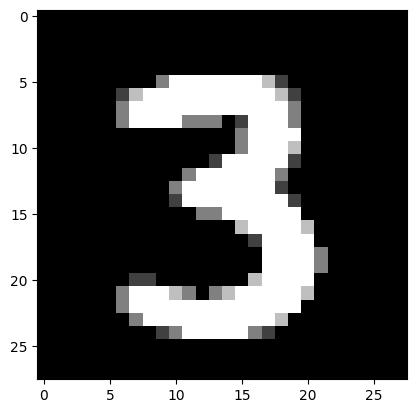

Prediction:  [0]
Label:  0


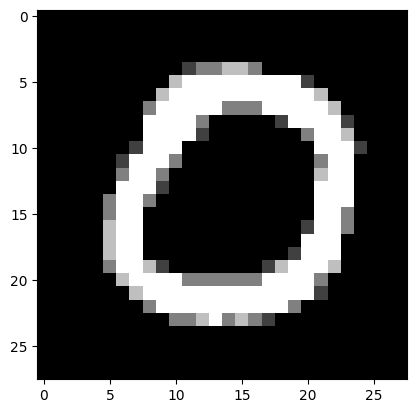

Prediction:  [0]
Label:  0


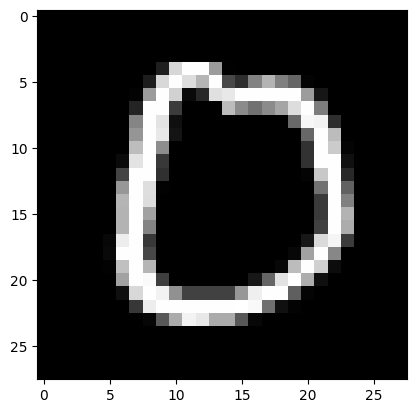

Prediction:  [9]
Label:  8


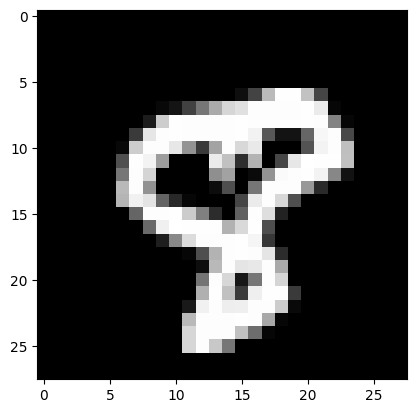

In [ ]:
# showing the results for some indices
test_prediction(0, W1, b1, W2, b2)
test_prediction(1, W1, b1, W2, b2)
test_prediction(2, W1, b1, W2, b2)
test_prediction(3, W1, b1, W2, b2)

In [ ]:
# finding accuracy on the cross validation set
dev_predictions = make_predictions(X_dev, W1, b1, W2, b2)
get_accuracy(dev_predictions, Y_dev)

[9 0 4 3 1 7 9 5 4 2 3 0 6 0 7 7 6 3 0 1 1 3 8 7 1 8 1 9 8 2 5 4 4 0 2 8 2
 5 9 3 7 5 7 0 1 6 7 7 1 8 2 0 6 0 3 8 9 1 2 0 1 4 0 8 5 6 6 9 2 6 6 8 2 6
 4 3 5 5 3 8 1 1 3 4 0 1 5 6 6 0 8 3 4 9 4 5 3 8 8 4 3 7 5 7 1 8 4 0 0 1 0
 7 3 9 7 7 0 5 2 3 8 7 1 1 1 0 6 8 3 0 1 4 4 2 1 8 3 1 9 8 1 9 9 8 5 3 1 8
 1 3 3 5 0 1 4 4 7 2 7 2 1 1 6 9 5 8 6 3 3 1 8 3 6 0 1 3 2 3 2 8 1 1 3 8 0
 4 0 0 6 1 5 3 0 3 3 2 2 1 6 5 9 6 0 1 1 1 8 5 2 1 9 0 0 6 4 9 9 5 4 4 9 1
 0 6 7 2 1 7 3 0 6 9 4 6 8 1 5 5 7 3 2 8 7 5 3 5 1 2 2 6 9 4 2 7 5 2 0 3 8
 0 6 5 9 7 4 2 6 4 8 6 5 8 9 6 1 8 1 0 4 8 8 2 0 9 9 8 0 6 7 1 3 6 8 4 9 1
 0 8 2 6 8 5 3 6 4 2 6 6 3 1 2 4 5 0 4 6 3 9 5 0 1 5 2 1 7 4 0 3 6 6 7 6 8
 7 2 6 8 0 7 8 5 9 3 3 9 5 1 2 3 0 1 8 8 7 2 5 1 4 6 1 6 9 0 8 2 3 4 3 5 8
 9 1 6 5 7 7 4 4 6 9 0 7 5 1 3 8 9 5 2 1 7 4 9 6 9 5 4 2 7 1 6 3 1 7 9 1 1
 6 0 6 1 1 0 0 9 4 4 5 7 7 6 9 0 8 8 2 6 7 9 3 0 8 4 2 8 5 1 8 1 3 0 9 0 9
 3 3 8 8 5 3 3 3 6 2 8 7 9 7 0 3 8 2 4 7 2 9 6 0 2 3 4 5 1 8 2 3 1 6 3 6 3
 0 2 3 9 3 2 6 2 8 3 4 1 

0.873

87.3% accuracy on the cross validation set

Now we are generating the neural networks with 2 hidden layers, the first one having 20 nodes and the second one as 10 nodes. This larger neural network is being run on the same dataset, with learning rate as 0.1 and number of iterations as 1000

In [ ]:
## defining all the functions similar to the above ones, with the only change in name by adding the prefix large in every name and defining the W1 and b1 as 20 nodes for 1st hidden layer and, W2 and b2 for 2nd hidden layer
def large_init_params():
    W1 = np.random.rand(20, 784) - 0.5
    b1 = np.random.rand(20, 1) - 0.5
    W2 = np.random.rand(10, 20) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    W3 = np.random.rand(10, 10) - 0.5
    b3 = np.random.rand(10, 1) - 0.5
    return W1, b1, W2, b2, W3, b3

def large_ReLU(Z):
    return np.maximum(Z, 0)

def large_softmax(Z):
    A = np.exp(Z) / sum(np.exp(Z))
    return A

def large_forward_prop(W1, b1, W2, b2, W3, b3, X):
    Z1 = W1.dot(X) + b1
    A1 = large_ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = large_ReLU(Z2)
    Z3 = W3.dot(A2) + b3
    A3 = large_softmax(Z3)
    return Z1, A1, Z2, A2, Z3, A3

def large_ReLU_deriv(Z):
    return Z > 0

def large_one_hot(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y

def large_backward_prop(Z1, A1, Z2, A2, W1, W2, A3, Z3, W3, X, Y):
    one_hot_Y = large_one_hot(Y)
    dZ3 = A3 - one_hot_Y
    dW3 = 1 / m * dZ3.dot(A2.T)
    db3 = 1 / m * np.sum(dZ3)
    dZ2 = W3.T.dot(dZ3) * large_ReLU_deriv(Z2)
    dW2 = 1 / m * dZ2.dot(A1.T)
    db2 = 1 /m * np.sum(dZ2)
    dZ1 = W2.T.dot(dZ2) * large_ReLU_deriv(Z1)
    dW1 = 1 / m * dZ1.dot(X.T)
    db1 = 1 / m * np.sum(dZ1)
    return dW1, db1, dW2, db2, dW3, db3

def large_update_params(W1, b1, W2, b2, W3, b3, dW1, db1, dW2, db2, dW3, db3, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    W3 = W3 - alpha * dW3
    b3 = b3 - alpha * db3

    return W1, b1, W2, b2, W3, b3

In [ ]:
def large_get_predictions(A3):
    return np.argmax(A3, 0)

def large_get_accuracy(predictions, Y):
    print(predictions, Y)
    return np.sum(predictions == Y) / Y.size

def large_gradient_descent(X, Y, alpha, iterations):
    W1, b1, W2, b2, W3, b3 = large_init_params()
    for i in range(iterations):
        Z1, A1, Z2, A2, Z3, A3 = large_forward_prop(W1, b1, W2, b2, W3, b3, X)
        dW1, db1, dW2, db2, dW3, db3 = large_backward_prop(Z1, A1, Z2, A2, W1, W2, A3, Z3, W3, X, Y)
        W1, b1, W2, b2, W3, b3 = large_update_params(W1, b1, W2, b2, W3, b3, dW1, db1, dW2, db2, dW3, db3, alpha)
        if i % 10 == 0:
            print("Iteration: ", i)
            predictions = large_get_predictions(A3)
            print(large_get_accuracy(predictions, Y))
    return W1, b1, W2, b2, W3, b3

In [ ]:
W1, b1, W2, b2, W3, b3 = large_gradient_descent(X_train, Y_train, 0.10, 1000)

Iteration:  0
[0 2 0 ... 5 0 0] [3 0 0 ... 5 8 6]
0.11451219512195122
Iteration:  10
[0 2 0 ... 3 2 6] [3 0 0 ... 5 8 6]
0.16707317073170733
Iteration:  20
[0 2 0 ... 3 0 3] [3 0 0 ... 5 8 6]
0.20102439024390245
Iteration:  30
[0 0 0 ... 3 0 3] [3 0 0 ... 5 8 6]
0.23275609756097562
Iteration:  40
[0 0 0 ... 3 0 3] [3 0 0 ... 5 8 6]
0.2580731707317073
Iteration:  50
[0 0 0 ... 3 0 3] [3 0 0 ... 5 8 6]
0.2832682926829268
Iteration:  60
[0 0 0 ... 3 2 6] [3 0 0 ... 5 8 6]
0.31102439024390244
Iteration:  70
[0 0 0 ... 3 8 6] [3 0 0 ... 5 8 6]
0.3417804878048781
Iteration:  80
[3 0 0 ... 3 8 6] [3 0 0 ... 5 8 6]
0.3758780487804878
Iteration:  90
[3 0 0 ... 2 8 6] [3 0 0 ... 5 8 6]
0.41597560975609754
Iteration:  100
[3 0 0 ... 2 8 6] [3 0 0 ... 5 8 6]
0.45170731707317074
Iteration:  110
[3 0 0 ... 2 8 6] [3 0 0 ... 5 8 6]
0.4806829268292683
Iteration:  120
[3 0 0 ... 2 8 6] [3 0 0 ... 5 8 6]
0.5055121951219512
Iteration:  130
[3 0 0 ... 2 8 6] [3 0 0 ... 5 8 6]
0.5289512195121951
Iteration:

Accuracy on the training set by using the larger neural networks with 2 hidden layers is 88.8%.
As it can be seen by increasing the number of layers in the neural networks the accuracy is increased.

In [ ]:
def large_make_predictions(X, W1, b1, W2, b2, W3, b3):
    _, _, _, _, _, A3 = large_forward_prop(W1, b1, W2, b2, W3, b3, X)
    predictions = get_predictions(A3)
    return predictions

def large_test_prediction(index, W1, b1, W2, b2, W3, b3):
    current_image = X_train[:, index, None]
    prediction = large_make_predictions(X_train[:, index, None], W1, b1, W2, b2, W3, b3)
    label = Y_train[index]
    print("Prediction: ", prediction)
    print("Label: ", label)

    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction:  [7]
Label:  7


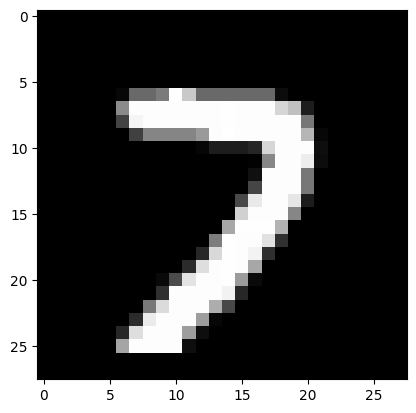

Prediction:  [2]
Label:  2


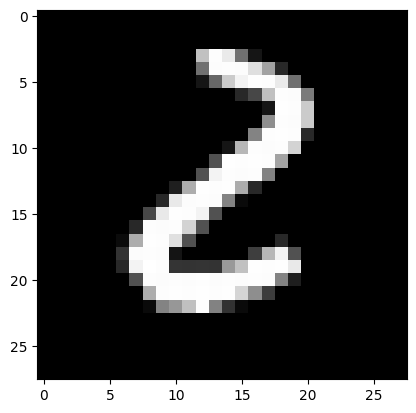

Prediction:  [4]
Label:  4


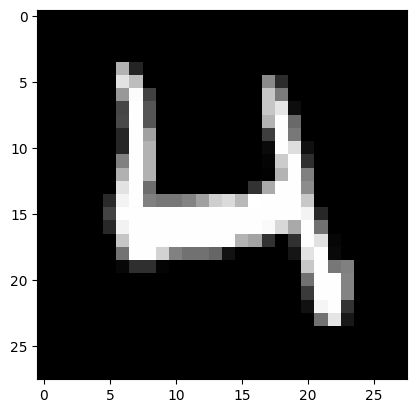

Prediction:  [8]
Label:  5


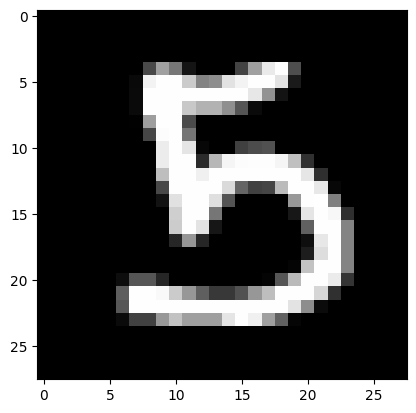

Prediction:  [6]
Label:  6


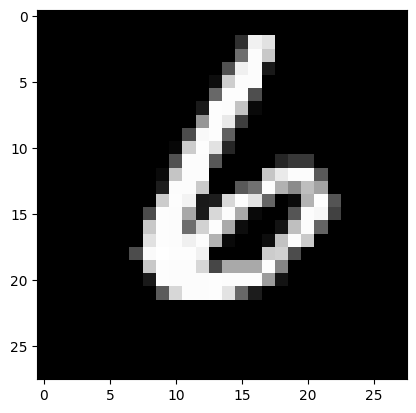

Prediction:  [7]
Label:  7


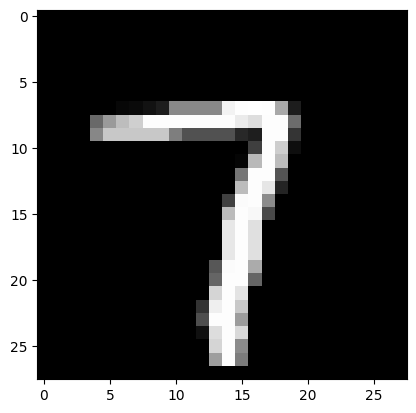

Prediction:  [6]
Label:  6


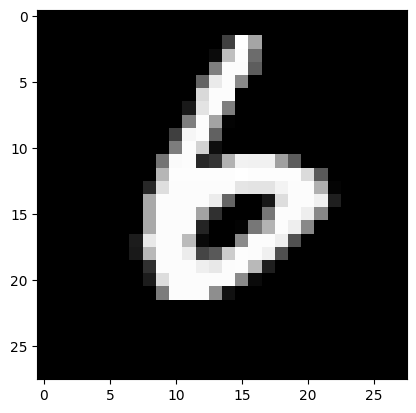

In [ ]:
large_test_prediction(4, W1, b1, W2, b2, W3, b3)
large_test_prediction(5, W1, b1, W2, b2, W3, b3)
large_test_prediction(6, W1, b1, W2, b2, W3, b3)
large_test_prediction(7, W1, b1, W2, b2, W3, b3)
large_test_prediction(8, W1, b1, W2, b2, W3, b3)
large_test_prediction(9, W1, b1, W2, b2, W3, b3)
large_test_prediction(10, W1, b1, W2, b2, W3, b3)

In [ ]:
large_dev_predictions = large_make_predictions(X_dev, W1, b1, W2, b2, W3, b3)
large_get_accuracy(large_dev_predictions, Y_dev)

[9 0 4 3 1 7 9 5 4 2 3 0 6 0 7 7 6 3 0 1 1 3 8 7 1 8 1 9 8 2 5 4 9 0 2 1 2
 5 9 3 7 5 7 0 1 6 7 7 1 8 2 0 6 0 3 8 9 1 3 0 1 9 0 8 5 6 6 9 1 6 6 8 2 6
 4 3 3 5 3 8 1 1 3 6 0 1 5 6 6 0 8 5 4 9 4 9 3 8 1 4 3 0 5 7 1 8 4 0 0 1 0
 7 3 9 7 7 0 5 6 3 3 7 1 1 1 0 6 3 3 0 1 4 4 2 1 8 9 1 9 8 2 9 7 8 5 3 1 8
 1 2 3 5 0 1 4 4 7 2 7 2 1 1 6 9 5 8 6 3 3 1 8 3 6 0 1 3 6 3 2 8 1 1 3 8 0
 4 0 8 6 1 5 5 0 3 3 2 6 1 6 5 9 6 3 1 1 1 3 3 2 1 9 0 0 6 4 9 9 5 4 7 9 1
 0 6 7 2 1 7 3 0 0 9 9 4 8 1 5 5 7 3 2 8 7 5 3 5 1 2 2 2 9 4 2 7 5 2 0 3 8
 0 6 5 9 2 4 2 8 4 8 6 8 8 9 6 1 8 1 0 4 8 8 6 0 9 9 8 0 6 9 1 3 6 8 4 9 1
 0 8 2 6 8 3 3 6 0 2 6 6 3 1 2 4 3 0 4 6 3 9 5 0 1 5 2 1 7 9 3 5 6 6 7 6 8
 9 2 6 8 0 7 8 5 9 3 3 9 3 1 2 3 0 1 8 8 9 2 5 1 9 6 1 6 9 0 8 2 3 4 5 5 8
 9 1 6 0 7 7 4 9 6 9 0 7 5 1 3 8 9 3 2 1 7 4 9 6 9 5 4 2 7 1 6 3 1 7 9 1 1
 6 0 0 1 1 0 0 7 4 4 5 7 7 6 9 0 1 8 1 6 7 9 3 0 8 4 2 8 5 1 8 1 3 5 9 0 9
 3 3 8 8 5 3 3 7 6 2 8 7 9 7 0 3 3 2 4 7 3 9 6 0 2 3 4 5 1 8 2 3 1 6 3 6 3
 0 9 3 9 3 2 6 2 8 3 9 1 

0.909

Finally, generated results on the cross validation set and the accuracy is now 90.9%, which is better than the neural network with the single hidden layer.